<a href="https://colab.research.google.com/github/francisco-mreina/olist-Predict-Insatisfaction-and-delay/blob/main/02_eda_seleccion_variables.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de clientes Olist (Brazilian E-Commerce)

##4.	Análisis Exploratorio de Datos (EDA) orientado los problemas de negocio

Hemos realizado el EDA con orders_analytical y order_items_integrada. Podemos usar lo ya realizado para analizar:

###4.1.	Evolución temporal y estacionalidad de pedidos
###4.2.	Distribución geográfica de pedidos y retrasos (problema 5)
###4.3.	Desempeño por categoría de producto (problema 5)
###4.4.	Métodos de pago y comportamiento de compra
###4.5.	Tiempos de entrega (estimado vs. real) (diagnóstico previo a problemas 1-2)
###4.6.	Relación entre variables clave y satisfacción (adelanto visual)

###4.1.	Evolución temporal y estacionalidad de pedidos

El objetivo de este análisis es identificar patrones temporales en la actividad de compra. Se estudia la evolución mensual y la distribución de pedidos por día de la semana y hora del día. Estos patrones servirán posteriormente para analizar si los periodos de mayor actividad presentan diferencias en insatisfacción o retrasos.

In [ ]:
# Evolución mensual del número de pedidos
pedidos_mes = (
    orders_analytical
    .groupby('order_purchase_month')
    .size()
    .reset_index(name='n_pedidos')
)

fig = px.line(pedidos_mes, x='order_purchase_month', y='n_pedidos', markers=True,
              title='Evolución mensual del número de pedidos')
fig.update_xaxes(tickangle=45)
fig.show()

In [ ]:
# Estacionalidad semanal y horaria
orden_dias = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

pedidos_dow = (
    orders_analytical['order_purchase_day']
    .value_counts()
    .reindex(orden_dias, fill_value=0)
)
fig = px.bar(pedidos_dow, title='Pedidos por día de la semana',
             labels={'value': 'nº de pedidos', 'index': 'día'})
fig.show()

pedidos_hora = orders_analytical['order_purchase_hour'].value_counts().sort_index()
fig = px.bar(pedidos_hora, title='Pedidos por hora del día',
             labels={'value': 'nº de pedidos', 'index': 'hora'})
fig.show()


Se observa un crecimiento sostenido de la actividad durante 2017, con máximos en fechas de Black Friday. La mayoría de las compras se hacen en días laborables, especialmente al principio de la semana, y en especial en jornada laboral.

###4.2.	Distribución geográfica de pedidos y retrasos (problema 5)

In [ ]:
# Pedidos por estado y por región del cliente
pedidos_estado = orders_analytical['customer_state'].value_counts().reset_index()
pedidos_estado.columns = ['customer_state', 'n_pedidos']

fig = px.bar(pedidos_estado, x='customer_state', y='n_pedidos',
             title='Pedidos por estado del cliente')
fig.show()

pedidos_region = orders_analytical['customer_region'].value_counts()
fig = px.pie(values=pedidos_region.values, names=pedidos_region.index,
             title='Pedidos por región del cliente')
fig.show()


In [ ]:
# Tasa de retraso por región (solo pedidos delivered, donde 'retraso' está definido)
retraso_region = (
    orders_analytical
    .loc[entregado]
    .groupby('customer_region')['retraso']
    .agg(['mean', 'count'])
    .rename(columns={'mean': 'tasa_retraso', 'count': 'n_pedidos'})
    .sort_values('tasa_retraso', ascending=False)
)
print(retraso_region)

fig = px.bar(retraso_region, y='tasa_retraso',
             title='Tasa de retraso en la entrega por región del cliente')
fig.show()


                 tasa_retraso  n_pedidos
customer_region                         
Nordeste             0.143299       9044
Norte                0.097996       1796
Centro-Oeste         0.079659       5624
Sudeste              0.074502      66200
Sur                  0.070508      13814


In [ ]:
# Mapa: retraso medio y volumen de pedidos por estado (usa lat/lng medios agregados en 5.2)
geo_estado = (
    orders_analytical
    .loc[entregado]
    .groupby('customer_state')
    .agg(lat=('lat_mean', 'mean'),
         lng=('lng_mean', 'mean'),
         tasa_retraso=('retraso', 'mean'),
         n_pedidos=('order_id', 'count'))
    .reset_index()
)

fig = px.scatter_geo(
    geo_estado, lat='lat', lon='lng', size='n_pedidos', color='tasa_retraso',
    hover_name='customer_state', scope='south america',
    title='Volumen de pedidos y tasa de retraso por estado'
)
fig.show()


Se demuestra, como se imaginaba, que la mayoría de compras se realizan en la región de Sao Paulo, con diferencia. La región sudeste concentra 7 de cada 10 compras hechas en Brasil. A su vez, las regiones con mayores retrasos son las del norte, evidenciando que el problema de los retrasos es muy concentrado y se debe a que la mayoría de vendedores se encuentra en las regiones sur también.

###4.3.	Desempeño por categoría de producto (problema 5)

Este apartado trabaja a granularidad ítem (`order_items_integrada`), tal y como se fijó en el capítulo 3.1, ya que la categoría de producto es una variable de ítem y agregarla a nivel de pedido (`categoria_principal`, la moda del pedido) perdería información en los pedidos multi-categoría.

In [ ]:
# Enriquecemos order_items_integrada con insatisfaccion y retraso del pedido al que pertenece cada ítem
items_reviews = order_items_integrada.merge(
    orders_analytical[['order_id', 'review_score', 'insatisfaccion', 'retraso']],
    on='order_id', how='left'
)

items_reviews['review_score'] = items_reviews['review_score'].astype(float)

cat_summary = items_reviews.groupby('product_category_name_english').agg(
    n_items=('order_item_id', 'count'),
    precio_medio=('price', 'mean'),
    flete_medio=('freight_value', 'mean'),
    review_medio=('review_score', 'mean'),
    tasa_insatisfaccion=('insatisfaccion', 'mean'),
    tasa_retraso=('retraso', 'mean'),
).sort_values('n_items', ascending=False)

cat_summary.head(15)


,n_items,precio_medio,flete_medio,review_medio,tasa_insatisfaccion,tasa_retraso
product_category_name_english,,,,,,
bed_bath_table,11115,93.296327,18.415928,3.898470,0.285290,0.083995
health_beauty,9670,130.163531,18.879703,4.141218,0.214271,0.090544
sports_leisure,8641,114.344285,19.512500,4.106864,0.218378,0.074131
furniture_decor,8334,87.564494,20.728258,3.906788,0.280898,0.084314
computers_accessories,7827,116.513903,18.821781,3.932537,0.266513,0.077708
housewares,6964,90.788148,20.986374,4.053195,0.240953,0.064901
watches_gifts,5991,201.135984,16.781160,4.018855,0.249708,0.082779
telephony,4545,71.213978,15.669041,3.945922,0.268647,0.083296
garden_tools,4347,111.630196,22.765758,4.045423,0.238325,0.079663


Las categorías con mayor volumen son bed, bath & table (11.115 ítems), health & beauty (9.670) y sports & leisure (8.641). Estas categorías concentran una parte importante de la actividad y, por tanto, tienen mayor impacto potencial sobre el negocio.

En términos de satisfacción, las valoraciones medias se sitúan aproximadamente entre 3,9 y 4,2 puntos. Destaca bed, bath & table, con una valoración de 3,90 y una tasa de insatisfacción del 28,5%, seguida de furniture & decor (28,1%). Por el contrario, perfumery, toys y cool stuff presentan valoraciones superiores a 4,14 y menores tasas de insatisfacción, mostrando un desempeño más favorable.

Respecto a la logística, las tasas de retraso son generalmente inferiores al 10%. Electronics presenta un 9,7% de retrasos, el nivel más elevado entre estas categorías de mayor volumen, mientras que housewares registra el menor nivel, con 6,5%.

En conjunto, bed, bath & table y furniture & decor requieren especial atención por combinar un volumen elevado con una satisfacción relativamente baja. Electronics, por su parte, destaca como categoría estratégica por su volumen y por presentar el mayor nivel de retrasos dentro de este grupo.

In [ ]:
# Top 15 categorías por volumen
top15 = cat_summary.head(15).reset_index()
fig = px.bar(top15, x='product_category_name_english', y='n_items',
             title='Top 15 categorías por volumen')
fig.update_xaxes(tickangle=45)
fig.show()


Intentamos descifrar si hay categorías con mayor tasa de insatisfacción y de retraso, exigiendo un mínimo de volumen de ventas por items como ponderación.

In [ ]:
min_items = 30
cat_relevante = cat_summary[cat_summary['n_items'] >= min_items]

peor_insatisfaccion = cat_relevante.sort_values('tasa_insatisfaccion', ascending=False).head(10)
peor_retraso = cat_relevante.sort_values('tasa_retraso', ascending=False).head(10)

print("Categorías con mayor tasa de insatisfacción (min. {} ítems):".format(min_items))
display(peor_insatisfaccion[['n_items', 'tasa_insatisfaccion']])

print("\nCategorías con mayor tasa de retraso (min. {} ítems):".format(min_items))
display(peor_retraso[['n_items', 'tasa_retraso']])


Categorías con mayor tasa de insatisfacción (min. 30 ítems):


,n_items,tasa_insatisfaccion
product_category_name_english,,
diapers_and_hygiene,39,0.538462
office_furniture,1691,0.400946
party_supplies,43,0.348837
home_comfort_2,30,0.333333
fashio_female_clothing,48,0.333333
fashion_male_clothing,132,0.333333
home_confort,434,0.329493
fixed_telephony,264,0.325758
audio,364,0.310440



Categorías con mayor tasa de retraso (min. 30 ítems):


,n_items,tasa_retraso
product_category_name_english,,
home_comfort_2,30,0.166667
furniture_mattress_and_upholstery,38,0.135135
audio,364,0.127072
fashion_underwear_beach,131,0.125984
christmas_supplies,153,0.120000
books_technical,267,0.110266
home_confort,434,0.102564
construction_tools_lights,304,0.099668
food,510,0.098196


Para cada categoría se calculan indicadores de volumen de ventas, precio y coste de envío, junto con métricas de experiencia del cliente: valoración media, tasa de insatisfacción y tasa de retrasos. Esto permite identificar no solo las categorías con mayor demanda, sino también aquellas que presentan mayores problemas de servicio.

En primer lugar, se identifican las 15 categorías con mayor volumen de productos vendidos, lo que permite centrar el análisis en las categorías con mayor impacto para el negocio.

Finalmente, se analizan las categorías con mayores tasas de insatisfacción y retrasos, considerando únicamente aquellas con al menos 30 ítems vendidos. Este umbral evita que categorías con muy pocas ventas aparezcan artificialmente entre las de peor desempeño y permite que los resultados sean más representativos para la toma de decisiones.

Los resultados muestran que diapers and hygiene presenta la mayor tasa de insatisfacción, sobre un volumen reducido de 39 ítems. Por su mayor relevancia en volumen, destaca especialmente office furniture, con 1.691 ítems y un 40,1% de insatisfacción, lo que la convierte en una categoría prioritaria para investigar. También presentan niveles elevados home comfort, fixed telephony y audio.

En cuanto a los retrasos, las tasas más elevadas corresponden a home comfort 2 (16,7%) y furniture, mattress and upholstery (13,5%), aunque ambas tienen un volumen reducido. Entre las categorías con mayor actividad destacan audio (12,7%), books technical (11,0%) y electronics (9,7%). Esta última es especialmente relevante por su elevado volumen, con 2.767 ítems.

En conjunto, los resultados sugieren que la insatisfacción no siempre está asociada exclusivamente a los retrasos, por lo que conviene analizar cada categoría de forma diferenciada. Como prioridades de negocio destacan office furniture, por su elevada insatisfacción y volumen, y electronics, por su gran volumen y una tasa de retraso relevante.

###4.4.	Métodos de pago y comportamiento de compra

In [ ]:
# Distribución de métodos de pago
pago_dist = orders_analytical['payment_type_principal'].value_counts()
fig = px.pie(
    values=pago_dist.values,
    names=pago_dist.index,
    title='Distribución de métodos de pago',
    width=700,
    height=500
)

fig.show()


In [ ]:
# Importe pagado según método de pago
fig = px.box(orders_analytical.dropna(subset=['payment_type_principal', 'total_payment']),
             x='payment_type_principal', y='total_payment',
             title='Importe total pagado según método de pago')
fig.show()


In [ ]:
# Número de cuotas
installments_dist = orders_analytical['max_installments'].value_counts().sort_index()
fig = px.bar(installments_dist, title='Distribución del número de cuotas',
             labels={'value': 'nº de pedidos', 'index': 'cuotas'},width=700, height=500
             )
fig.show()

# Relación cuotas-importe: ¿los pagos a más plazos son de mayor importe?
cuotas_importe = orders_analytical.groupby('max_installments')['total_payment'].mean()
fig = px.line(cuotas_importe, markers=True,
              title='Importe medio pagado según nº de cuotas')
fig.show()


- Dominio de la Tarjeta de Crédito: La tarjeta de crédito es, con diferencia, el método de pago más utilizado por los clientes, lo que sugiere que es fundamental optimizar y asegurar este canal para maximizar las conversiones.

- Compras de Mayor Valor a Plazos: Los clientes tienden a utilizar más cuotas para compras de mayor importe, especialmente con la tarjeta de crédito. Esto indica que ofrecer opciones de financiación flexibles es clave para facilitar la adquisición de productos de mayor valor y puede ser una estrategia para aumentar el ticket medio.

- Gestión de Riesgos y Promociones: La relación entre el tipo de pago, el número de cuotas y el valor de la compra puede ser un indicador importante para predecir la satisfacción del cliente y el riesgo. Por ejemplo, las compras a muchos plazos podrían asociarse a un mayor riesgo percibido, lo que es relevante para estrategias de retención o para diseñar promociones segmentadas. Comprender estas dinámicas permite adaptar ofertas y condiciones de pago para diferentes segmentos de clientes y categorías de productos.


###4.5.	Tiempos de entrega (estimado vs. real) (diagnóstico previo a problemas 1-2)

Se reutiliza la función `histogram_boxplot` definida en el capítulo 3 (histograma + boxplot con media/mediana), aplicada ahora sobre las variables derivadas del capítulo 6, manteniendo el mismo estilo visual que el resto de la memoria.

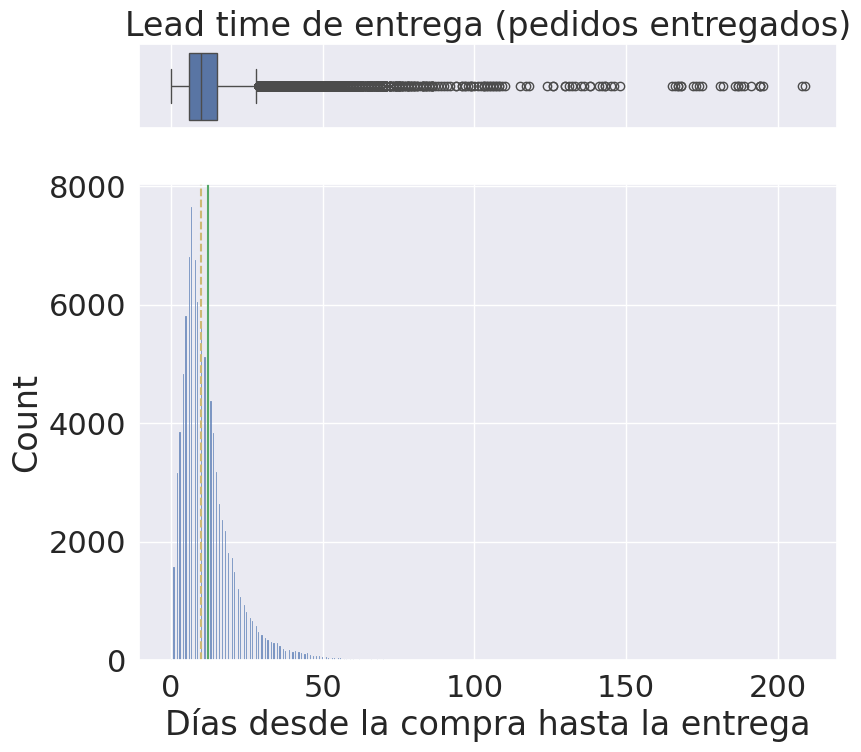

In [ ]:
histogram_boxplot(
    orders_analytical.loc[entregado, 'lead_time_dias'].dropna(),
    xlabel='Días desde la compra hasta la entrega',
    title='Lead time de entrega (pedidos entregados)'
)


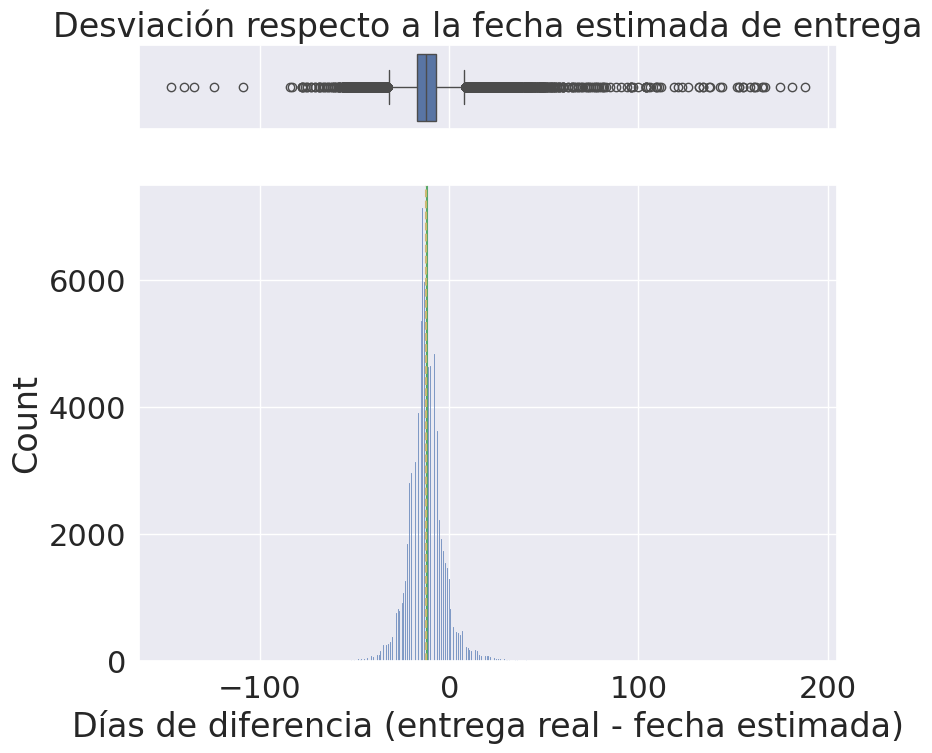

In [ ]:
histogram_boxplot(
    orders_analytical.loc[entregado, 'delta_entrega_dias'].dropna(),
    xlabel='Días de diferencia (entrega real - fecha estimada)',
    title='Desviación respecto a la fecha estimada de entrega'
)


In [ ]:
# Evolución mensual de la fecha estimada vs. la fecha real de entrega
entrega_mensual = (
    orders_analytical
    .loc[entregado]
    .assign(mes=lambda d: d['order_purchase_timestamp'].dt.to_period('M').astype(str))
    .groupby('mes')
    .agg(lead_time_medio=('lead_time_dias', 'mean'),
         delta_medio=('delta_entrega_dias', 'mean'))
    .reset_index()
)

fig = px.line(entrega_mensual, x='mes', y=['lead_time_medio', 'delta_medio'],
              title='Evolución mensual del lead time medio y de la desviación media sobre lo estimado')
fig.update_xaxes(tickangle=45)
fig.show()


- Tiempo Total de Entrega (lead_time_dias): Este gráfico ilustra el tiempo que transcurre desde que un cliente realiza un pedido hasta que lo recibe. Es un indicador fundamental de nuestra eficiencia logística. Nos permite comprender cuál es nuestro tiempo de entrega típico y si existen entregas excepcionalmente largas, que podrían señalar problemas en la cadena de suministro o con ciertos tipos de productos/ubicaciones. Desde una perspectiva de negocio, optimizar este tiempo es clave para mejorar la experiencia del cliente y nuestra competitividad en el mercado.

- Desviación de la Fecha Estimada de Entrega (delta_entrega_dias): Este indicador mide directamente nuestra capacidad para cumplir las promesas de entrega. Un valor negativo significa que el pedido se entregó antes de lo estimado (un factor que genera una experiencia positiva en el cliente), mientras que un valor positivo indica un retraso. El análisis muestra que la mayoría de las entregas se realizan antes o en la fecha estimada, lo cual es un punto fuerte. Sin embargo, la 'cola larga' de valores positivos (los retrasos) es donde reside el riesgo principal, ya que son estos incidentes, aunque sean una minoría, los que mayor insatisfacción generan. Identificar las causas raíz de estos retrasos es crítico.

- Evolución Mensual del Rendimiento de Entrega: Este gráfico nos permite observar cómo el tiempo medio total de entrega y la desviación media respecto a lo estimado varían a lo largo de los meses. Es esencial para detectar patrones estacionales, identificar si nuestro rendimiento de entrega está mejorando o empeorando con el tiempo, y reconocer posibles picos de demanda que podrían poner a prueba nuestra capacidad operativa. Esta información es vital para una planificación logística proactiva, la asignación eficiente de recursos y para establecer expectativas de entrega realistas para nuestros clientes durante todo el año.



###4.6.	Relación entre variables clave y satisfacción (adelanto visual)

Este apartado corresponde a la **fase a priori** del flujo de modelización adjuntado al proyecto (relaciones entre predictores y relaciones con la variable objetivo, contrastadas con análisis estadístico chi²/t-test/ANOVA antes de plantear cualquier modelo). Aquí se aplica esa misma lógica sobre `insatisfaccion` como adelanto visual y estadístico de la modelización del capítulo 6, distinguiendo entre predictores categóricos (test chi-cuadrado de independencia) y predictores numéricos (t-test de diferencia de medias entre satisfechos e insatisfechos).

In [ ]:
# Relación entre variables CATEGÓRICAS y satisfacción (test chi-cuadrado de independencia)
cat_vars = ['payment_type_principal', 'customer_region', 'cliente_recurrente']

for var in cat_vars:
    tabla = pd.crosstab(orders_analytical[var], orders_analytical['insatisfaccion'])
    chi2, p, dof, exp = stats.chi2_contingency(tabla)
    print(f"{var:25s} vs insatisfaccion  ->  chi2={chi2:8.2f}  p={p:.4g}  {'(significativo)' if p < 0.05 else '(no significativo)'}")


payment_type_principal    vs insatisfaccion  ->  chi2=   31.95  p=1.957e-06  (significativo)
customer_region           vs insatisfaccion  ->  chi2=  171.17  p=5.855e-36  (significativo)
cliente_recurrente        vs insatisfaccion  ->  chi2=    0.84  p=0.36  (no significativo)


In [ ]:
# Relación entre variables NUMÉRICAS y satisfacción (t-test de Welch entre grupos)
num_vars = ['lead_time_dias', 'delta_entrega_dias', 'total_price', 'total_freight', 'max_installments']

for var in num_vars:
    grupo0 = orders_analytical.loc[orders_analytical['insatisfaccion'] == 0, var].dropna()
    grupo1 = orders_analytical.loc[orders_analytical['insatisfaccion'] == 1, var].dropna()
    t, p = stats.ttest_ind(grupo0, grupo1, equal_var=False)
    print(f"{var:20s} media_satisfechos={grupo0.mean():8.2f}  media_insatisfechos={grupo1.mean():8.2f}  "
          f"t={t:7.2f}  p={p:.4g}  {'(significativo)' if p < 0.05 else '(no significativo)'}")


lead_time_dias       media_satisfechos=   10.69  media_insatisfechos=   17.41  t= -66.51  p=0  (significativo)
delta_entrega_dias   media_satisfechos=  -13.08  media_insatisfechos=   -7.34  t= -55.80  p=0  (significativo)
total_price          media_satisfechos=  134.44  media_insatisfechos=  149.31  t=  -8.35  p=6.946e-17  (significativo)
total_freight        media_satisfechos=   21.92  media_insatisfechos=   25.98  t= -20.85  p=7.39e-96  (significativo)
max_installments     media_satisfechos=    2.89  media_insatisfechos=    3.08  t=  -9.13  p=7.381e-20  (significativo)


In [ ]:
# Visualización: desviación de entrega según la valoración recibida
fig = px.box(
    orders_analytical.dropna(subset=['delta_entrega_dias', 'review_score']),
    x='review_score', y='delta_entrega_dias',
    title='Desviación respecto a la entrega estimada, según valoración (review_score)'
)
fig.show()


In [ ]:
# Matriz de correlación entre variables numéricas clave y review_score
num_cols = ['review_score', 'delta_entrega_dias', 'lead_time_dias',
            'total_price', 'total_freight', 'max_installments', 'n_items']

corr = orders_analytical[num_cols].corr()

fig = px.imshow(corr, text_auto='.2f', color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                 title='Matriz de correlación — variables clave vs review_score')
fig.show()


Para identificar qué factores están relacionados con la insatisfacción del cliente, se han aplicado pruebas estadísticas de asociación y comparación de medias. Los resultados muestran que el tipo de pago y la región del cliente presentan una relación estadísticamente significativa con la insatisfacción. En cambio, ser un cliente recurrente no muestra una relación significativa, por lo que no se puede afirmar que la recurrencia del cliente esté asociada a una mayor o menor insatisfacción.

En las variables numéricas, sí se observan diferencias significativas entre clientes satisfechos e insatisfechos. Los clientes insatisfechos presentan un tiempo medio de entrega mayor (17,41 días frente a 10,69), lo que refuerza la importancia de los plazos de entrega en la experiencia del cliente. También presentan un delta de entrega menos favorable (-7,34 frente a -13,08 días), indicando que los pedidos de clientes satisfechos suelen entregarse con mayor margen respecto al plazo previsto.

Además, los clientes insatisfechos realizan, en promedio, pedidos de mayor importe (149,31 frente a 134,44) y soportan mayores costes de envío (25,98 frente a 21,92). También utilizan ligeramente más cuotas de pago (3,08 frente a 2,89). Aunque estas diferencias son estadísticamente significativas, su relevancia práctica debe interpretarse junto con el resto de factores.

En conjunto, los resultados apuntan a que los tiempos y condiciones de entrega son algunos de los factores más claramente relacionados con la insatisfacción, mientras que variables como la región y el tipo de pago también presentan diferencias que conviene considerar en análisis posteriores.

##5. Feature engineering (previo a modelización)

In [ ]:
# Función para calcular VCramer (dos nominales de entrada!)
def cramers_v(var1, varObj):
    if not var1.dtypes.name == 'category':
        #bins = min(5,var1.value_counts().count())
        var1 = pd.cut(var1, bins = 5)
    if not varObj.dtypes.name == 'category': #np.issubdtype(varObj, np.number):
        #bins = min(5,varObj.value_counts().count())
        varObj = pd.cut(varObj, bins = 5)

    data = pd.crosstab(var1, varObj).values
    vCramer = stats.contingency.association(data, method = 'cramer')
    return vCramer

In [ ]:
#Recobramos las variables objetivo como categóricas para poder utilizar Cramer
insatisfaccion = orders_analytical['insatisfaccion'].astype('category')
retraso = orders_analytical['retraso'].astype('category')

#Primero creamos un imput para poder analizar los predictores
imput = orders_analytical.drop(['retraso', 'insatisfaccion'],axis=1)

#Eliminamos las variables que pueden afecar a la calidad de los datos, creadas para investigación previa.
#Estas variables introducen data leakage
imput = imput.drop(['lead_time_dias', 'delta_entrega_dias', 'cliente_recurrente', 'cliente_recurrente'],axis=1)

#Para hacer un análisis sin ruido creamos dos variables aleatorias, para saber qué variables son relevantes y cuáles no
imput['aleatorio'] = np.random.uniform(0, 1, size=imput.shape[0])
imput['aleatorio2'] = np.random.uniform(0, 1, size=imput.shape[0])
imput['customer_region'] = imput['customer_region'].astype('category')

In [ ]:
imput.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 38 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  object        
 1   customer_id                    99441 non-null  object        
 2   order_status                   99441 non-null  category      
 3   order_purchase_timestamp       99441 non-null  datetime64[ns]
 4   order_approved_at              99295 non-null  datetime64[ns]
 5   order_delivered_carrier_date   97660 non-null  datetime64[ns]
 6   order_delivered_customer_date  96484 non-null  datetime64[ns]
 7   order_estimated_delivery_date  99441 non-null  datetime64[ns]
 8   customer_unique_id             99441 non-null  object        
 9   customer_zip_code_prefix       99441 non-null  string        
 10  customer_city                  99441 non-null  object        
 11  customer_state 

###5.1 Adicional, Análisis de variables para modelización



In [ ]:
#Numericas

num_vars = [col for col in num_vars if col in imput.columns]

# 1. VARIABLES CATEGÓRICAS

categorical_features = imput.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

for col in categorical_features:
    print(
        f"{col:35} "
        f"{imput[col].nunique():6} categorías"
    )

# 2. CRAMER
cramer_candidates = categorical_features + ['aleatorio', 'aleatorio2']

for col in categorical_features:
    if imput[col].dtypes.name != 'category':
        imput[col] = imput[col].astype('category')

cramer_results = pd.DataFrame(
    imput[cramer_candidates].apply(lambda x: cramers_v(x, insatisfaccion)),
    columns=['VCramer']
).sort_values('VCramer', ascending=False)

print(cramer_results)

umbral_ruido = cramer_results.loc[['aleatorio', 'aleatorio2'], 'VCramer'].max()
print(f"\nUmbral de ruido (max entre aleatorio/aleatorio2): {umbral_ruido:.4f}")

no_informativas = cramer_results[cramer_results['VCramer'] <= umbral_ruido].index.tolist()
print(f"Variables categóricas no informativas (por debajo del ruido): {no_informativas}")

# 3. CARDINALIDAD

cardinality = (
    imput[categorical_features]
    .nunique()
    .sort_values(ascending=False)
)

print(cardinality)

# 4. VARIABLES CONSTANTES

constant_vars = [
    col
    for col in num_vars
    if imput[col].nunique() <= 1
]

print("Variables constantes:")
print(constant_vars)

# 5. RESUMEN

print("=" * 60)
print("RESUMEN")
print("=" * 60)

print("Observaciones:", len(imput))
print("Variables:", imput.shape[1])

print("\nTop 10 por correlación (Pearson, numéricas):")
print(corr.head(10))

print("\nTop 10 categóricas por Cramér's V:")
print(cramer_results.head(10))

order_id                             99441 categorías
customer_id                          99441 categorías
order_status                             8 categorías
customer_unique_id                   96096 categorías
customer_zip_code_prefix             14994 categorías
customer_city                         4119 categorías
customer_state                          27 categorías
customer_region                          5 categorías
categoria_principal                     74 categorías
payment_type_principal                   5 categorías
review_score                             5 categorías
city_mean                             4057 categorías
state_mean                              27 categorías
order_purchase_month                    25 categorías
order_purchase_day                       7 categorías
                           VCramer
order_id                  1.000000
customer_id               1.000000
review_score              1.000000
customer_unique_id        0.990499
customer_zip_co

###5.1 Variables relevantes en la predicción de insatisfacción del cliente

En este listado no se incluye: review_score (es lo que se pretende predecir más adelante) ni las variables de creación de la valoración, pues son posteriores al hecho que se quiere predecir en el apartado 6: review_creation_date, review_answer_timestamp'

In [ ]:
# Establecemos las variables que queremos comprobar como potenciales predictores.

predictores_insat = ['order_status', 'customer_region','total_price','order_approved_at', 'order_delivered_customer_date',
               'order_estimated_delivery_date', 'order_delivered_carrier_date', 'total_freight', 'n_items','n_sellers_distintos',
               'peso_total_g', 'total_payment','n_pagos', 'max_installments', 'payment_type_principal', 'lat_mean', 'lng_mean',
               'dias_aprobacion', 'order_purchase_hour','ticket_medio_item', 'pct_flete',
               'aleatorio', 'aleatorio2',]


In [ ]:
# Ranking frente a insatisfaccion
TCramer_insat = pd.DataFrame(imput[predictores_insat].apply(lambda x: cramers_v(x, insatisfaccion)),
    columns=['VCramer'])

px.bar(TCramer_insat, x=TCramer_insat.VCramer,
       height=900,
       title='Importancia de variables frente a Insatisfaccion del cliente').update_yaxes(categoryorder="total ascending")

In [ ]:
# Listado de variables ordenadas por importancia
print("Variables ordenadas por V de Cramér:\n")

for variable, valor in TCramer_insat.sort_values(
    'VCramer', ascending=False
)['VCramer'].items():
    print(f"- {variable}: V de Cramér = {valor:.4f}")

Variables ordenadas por V de Cramér:

- order_status: V de Cramér = 0.2505
- n_sellers_distintos: V de Cramér = 0.1040
- order_approved_at: V de Cramér = 0.0946
- order_delivered_carrier_date: V de Cramér = 0.0838
- order_delivered_customer_date: V de Cramér = 0.0744
- order_estimated_delivery_date: V de Cramér = 0.0682
- customer_region: V de Cramér = 0.0415
- lat_mean: V de Cramér = 0.0354
- n_items: V de Cramér = 0.0289
- max_installments: V de Cramér = 0.0270
- lng_mean: V de Cramér = 0.0269
- peso_total_g: V de Cramér = 0.0228
- pct_flete: V de Cramér = 0.0221
- payment_type_principal: V de Cramér = 0.0179
- order_purchase_hour: V de Cramér = 0.0127
- total_freight: V de Cramér = 0.0125
- ticket_medio_item: V de Cramér = 0.0099
- total_payment: V de Cramér = 0.0085
- dias_aprobacion: V de Cramér = 0.0083
- total_price: V de Cramér = 0.0075
- aleatorio2: V de Cramér = 0.0066
- n_pagos: V de Cramér = 0.0036
- aleatorio: V de Cramér = 0.0030


###5.2 Variables relevantes en la predicción de retraso en la entrega

In [ ]:
# Ranking frente a retraso
predictores_retraso = ['customer_region','total_price','order_approved_at', 'order_delivered_carrier_date', 'total_freight', 'n_items',
                       'n_sellers_distintos', 'peso_total_g', 'total_payment','n_pagos', 'max_installments', 'payment_type_principal',
                       'lat_mean', 'lng_mean', 'order_purchase_hour','ticket_medio_item', 'pct_flete','aleatorio', 'aleatorio2',]

TCramer_retraso = pd.DataFrame(imput[predictores_retraso].apply(lambda x: cramers_v(x, retraso)), columns=['VCramer']
)
px.bar(TCramer_retraso, x=TCramer_retraso.VCramer,
       height=900,
       title='Importancia de variables frente a retraso en la entrega'
       ).update_yaxes(categoryorder="total ascending")

In [ ]:
# Listado 2 de variables ordenadas por importancia
print("Variables ordenadas por V de Cramér:\n")

for variable, valor in TCramer_retraso.sort_values(
    'VCramer', ascending=False
)['VCramer'].items():
    print(f"- {variable}: V de Cramér = {valor:.4f}")

Variables ordenadas por V de Cramér:

- order_approved_at: V de Cramér = 0.1460
- order_delivered_carrier_date: V de Cramér = 0.1197
- customer_region: V de Cramér = 0.0745
- lat_mean: V de Cramér = 0.0569
- lng_mean: V de Cramér = 0.0356
- n_sellers_distintos: V de Cramér = 0.0284
- ticket_medio_item: V de Cramér = 0.0147
- payment_type_principal: V de Cramér = 0.0147
- order_purchase_hour: V de Cramér = 0.0120
- max_installments: V de Cramér = 0.0086
- pct_flete: V de Cramér = 0.0076
- n_items: V de Cramér = 0.0070
- peso_total_g: V de Cramér = 0.0055
- total_price: V de Cramér = 0.0052
- aleatorio: V de Cramér = 0.0050
- total_payment: V de Cramér = 0.0043
- aleatorio2: V de Cramér = 0.0041
- n_pagos: V de Cramér = 0.0033
- total_freight: V de Cramér = 0.0017


###5.3.	Tratamiento de outliers, encoding y normalización

Para el próximo paso (modelización predictiva) antes de nada, cogemos aquellas variables numéricas con gran asimetría y le aplicamos una normalización con la fórmula de gestiona_outliers del punto 3, que dejamos pendiente para no sacar en los pasos siguientes conclusiones erróneas.

In [ ]:
# Comprobamos primero en modo 'check' antes de decidir el tratamiento de dias_aprobacion
lower, upper, total = gestiona_outliers(imput['dias_aprobacion'], clas='check')
print(f"dias_aprobacion -> % marcado como outlier: {total:.2f}%")

dias_aprobacion
dias_aprobacion -> % marcado como outlier: 17.54%


In [ ]:
var_num = ['total_price', 'total_freight', 'dias_aprobacion']
for col in var_num:
    imput[col] = gestiona_outliers(imput[col], clas='winsor')

imput['payment_type_principal'] = imput['payment_type_principal'].astype('category')
imput['customer_region'] = imput['customer_region'].astype('category')

total_price
total_freight
dias_aprobacion
